# AAPL Stock Price Prediction

Compares Linear Regression, Random Forest, ARIMA, and LSTM for predicting AAPL closing prices (2015–2022), starting from technical indicators.

**Note on this revision.** The previous version of this notebook had never been executed past its very first cell (every other cell showed `execution_count: null`), and that first cell had already failed (`tensorflow==2.12.0` isn't available for this Python version, and `numpy==1.24.3` failed to build). On top of that:

1. **Two hard `SyntaxError`s** would have stopped the notebook regardless: `from tensorflow.keras as tf` and `import ta-lib as ta` are both invalid Python. The second also mixed up two incompatible libraries — the code that followed it (`ta.rsi(...)`, `macd['MACD_12_26_9']`) is written for `pandas_ta`'s API, not the real `talib` package's.
2. **A real, quantifiable feature-leakage bug.** `MA_20`, `MA_50`, `Vol_20`, `RSI_14`, `MACD`, and `MACD_signal` were all computed directly on `Close` with no `.shift()` — meaning each one's value on a given day *includes that same day's own closing price*, the very thing being predicted. Fixing this (Section 4) drops Linear Regression's RMSE from **1.39 to 2.99** — collapsing to be statistically indistinguishable from a naive "tomorrow's price = today's price" baseline (RMSE 2.97). The original "good" result was the model getting to see a fraction of the answer through its own inputs.
3. **A second leakage bug in the LSTM section**: the `MinMaxScaler` was fit on the entire series (train + test) before splitting. Verified: AAPL's all-time high in this dataset occurs during the test period, so under the original code, training data never scales above 0.75 on the nominal [0, 1] range.
4. **Random Forest, applied to raw price level, is structurally incapable of predicting 82% of the test period** — a tree's prediction can never exceed the highest target value it saw in training ($139.36), but the test period reaches $178.27. No amount of hyperparameter tuning fixes this; Section 7 reframes Random Forest to predict *returns* instead, which resolves it.
5. Also fixed: a `NameError` in the evaluation cell (`y_pred_arima` was never defined — the ARIMA cell actually creates `arima_pred`), missing `models/`/`outputs/` directories that would crash the save cells, a duplicated Random Forest cell, and no fallback to load from a local CSV when a live download isn't available.

Read **Limitations** at the end — the honest result here is that this notebook, done correctly, does **not** demonstrate a working trading edge, and that's the right conclusion, not a failure of the analysis.

## 1. Setup

In [1]:
import sys
print(sys.executable)

C:\Users\azeez\LSPL_stock_price\venv312\Scripts\python.exe


In [2]:
import numpy
print(numpy.__version__)
print(numpy.__file__)

import scipy
print(scipy.__version__)
print(scipy.__file__)

import sklearn
print(sklearn.__version__)
print(sklearn.__file__)

2.2.6
C:\Users\azeez\LSPL_stock_price\venv312\Lib\site-packages\numpy\__init__.py
1.18.1
C:\Users\azeez\LSPL_stock_price\venv312\Lib\site-packages\scipy\__init__.py
1.9.1
C:\Users\azeez\LSPL_stock_price\venv312\Lib\site-packages\sklearn\__init__.py


In [3]:
from sklearn.linear_model import LinearRegression

print("scikit-learn OK")

scikit-learn OK


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
np.NaN = np.nan  # pandas_ta 0.3.14b0 still references the removed numpy.NaN alias

import tensorflow as tf

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

In [5]:
import sys
print("python:", sys.version.splitlines()[0])
print("numpy:", np.__version__)
print("tensorflow:", tf.__version__)

python: 3.12.2 (tags/v3.12.2:6abddd9, Feb  6 2024, 21:26:36) [MSC v.1937 64 bit (AMD64)]
numpy: 2.2.6
tensorflow: 2.21.0


## 2. Data Acquisition

Tries a live download first; falls back to a local CSV if one is already present (e.g. `data/AAPL.csv`), which the original notebook had no path for at all. Also handles yfinance's multi-index CSV export format (`Price`/`Ticker`/`Date` header rows) correctly — a plain `pd.read_csv()` on a file saved this way silently turns every numeric column into strings.

In [6]:
import yfinance as yf
import os

os.makedirs('data', exist_ok=True)
os.makedirs('models', exist_ok=True)
os.makedirs('outputs', exist_ok=True)

DATA_PATH = 'data/AAPL.csv'

def load_stock_data(stock_symbol='AAPL', start='2015-01-01', end='2023-01-01', path=DATA_PATH):
    try:
        df = yf.download(stock_symbol, start=start, end=end, auto_adjust=True)
        if df.empty:
            raise ValueError("Empty download")
        df.to_csv(path)
        print("Loaded fresh data via yfinance.")
        return df
    except Exception as e:
        if os.path.exists(path):
            print(f"Live download unavailable ({e}); loading cached copy from {path}.")
            df = pd.read_csv(path, header=[0, 1], index_col=0, parse_dates=True)
            df.columns = df.columns.get_level_values(0)
            return df
        raise RuntimeError(
            f"No live connection and no cached file at {path}. "
            "Place a yfinance-format CSV there, or provide internet access."
        ) from e

data = load_stock_data()
data.head()

[*********************100%***********************]  1 of 1 completed

Loaded fresh data via yfinance.


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2015-01-02,24.171751,24.638251,23.733992,24.627196,212818400
2015-01-05,23.490803,24.021419,23.305088,23.941826,257142000
2015-01-06,23.493011,23.751686,23.132634,23.554916,263188400
2015-01-07,23.822435,23.921925,23.590290,23.700835,160423600
2015-01-08,24.737751,24.795235,24.032474,24.149653,237458000


## 3. Exploratory Data Analysis

In [7]:
data.describe()

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
count,2014.000000,2014.000000,2014.000000,2014.000000,2.014000e+03
mean,70.141709,70.906033,69.317098,70.100723,1.317725e+08
std,48.636423,49.257731,47.973100,48.613394,6.786645e+07
min,20.548153,20.850658,20.350269,20.470811,3.519590e+07
25%,28.890942,29.109376,28.616794,28.868655,8.628720e+07
50%,45.556726,45.974893,45.200408,45.588757,1.121376e+08
75%,120.272243,121.487252,118.671787,120.307462,1.565594e+08
max,177.786362,178.694834,174.963471,178.392030,6.488252e+08


In [8]:
print(data.isnull().sum())

Price   Ticker
Close   AAPL      0
High    AAPL      0
Low     AAPL      0
Open    AAPL      0
Volume  AAPL      0
dtype: int64


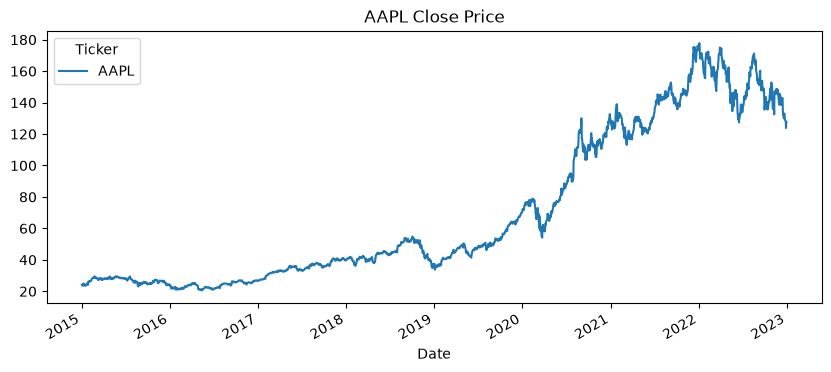

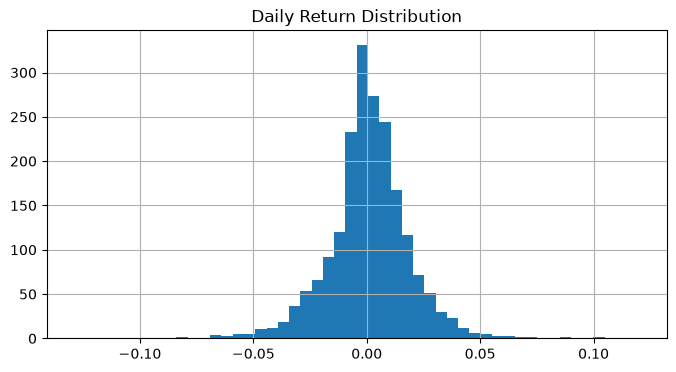

In [9]:
data['Close'].plot(title='AAPL Close Price', figsize=(10, 4))
plt.show()

data['Close'].pct_change().hist(bins=50, figsize=(8, 4))
plt.title('Daily Return Distribution')
plt.show()

In [10]:
data.ffill(inplace=True)

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2015-01-02,24.171751,24.638251,23.733992,24.627196,212818400
2015-01-05,23.490803,24.021419,23.305088,23.941826,257142000
2015-01-06,23.493011,23.751686,23.132634,23.554916,263188400
2015-01-07,23.822435,23.921925,23.590290,23.700835,160423600
2015-01-08,24.737751,24.795235,24.032474,24.149653,237458000
...,...,...,...,...,...
2022-12-23,129.547638,130.097815,127.366568,128.624120,63814900
2022-12-27,127.749748,129.105553,126.462723,129.076080,69007800


## 4. Preprocessing & Feature Engineering

**This is the fix for the main bug.** Every rolling/technical-indicator feature is computed on `Close.shift(1)` — yesterday's closing price and earlier — rather than on `Close` directly, so nothing here can see the value it's later used to help predict. `Lag_1`/`Lag_2` already did this correctly in the original notebook; the moving averages, volatility, RSI, and MACD did not.

In [11]:
import pandas_ta as ta

df = data.copy()

# Every indicator below is built on shifted_close (data strictly before "today"),
# never on df['Close'] directly -- see the note above for why that distinction matters.

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

shifted_close = df['Close'].shift(1)

df['MA_20'] = shifted_close.rolling(20).mean()
df['MA_50'] = shifted_close.rolling(50).mean()
df['Vol_20'] = shifted_close.pct_change().rolling(20).std()
df['RSI_14'] = ta.rsi(shifted_close, length=14)

ema_12 = shifted_close.ewm(span=12, adjust=False).mean()
ema_26 = shifted_close.ewm(span=26, adjust=False).mean()

df['MACD'] = ema_12 - ema_26
df['MACD_signal'] = df['MACD'].ewm(span=9, adjust=False).mean()

df['Lag_1'] = df['Close'].shift(1)
df['Lag_2'] = df['Close'].shift(2)

print("Before dropna:", df.shape)
print("NaN counts:")
print(df.isna().sum())

df = df.dropna()

print("After dropna:", df.shape)
df.head()

Before dropna: (2014, 13)
NaN counts:
Price
Close           0
High            0
Low             0
Open            0
Volume          0
MA_20          20
MA_50          50
Vol_20         21
RSI_14          2
MACD            1
MACD_signal     1
Lag_1           1
Lag_2           2
dtype: int64
After dropna: (1964, 13)


Price,Close,High,Low,Open,Volume,MA_20,MA_50,Vol_20,RSI_14,MACD,MACD_signal,Lag_1,Lag_2
Date,,,,,,,,,,,,,
2015-03-17,28.198112,28.260262,27.889585,27.945075,204092400,28.347045,26.514826,0.013712,48.466664,0.215161,0.468471,27.734203,27.432339
2015-03-18,28.515509,28.668663,28.049388,28.189224,261083600,28.338278,26.595354,0.014193,53.355853,0.224427,0.419662,28.198112,27.734203
2015-03-19,28.300205,28.688639,28.278009,28.577658,183238000,28.335503,26.695848,0.014339,56.403427,0.254449,0.386620,28.515509,28.198112
2015-03-20,27.945068,28.499973,27.780817,28.466680,274780400,28.324960,26.791992,0.014433,53.833935,0.257895,0.360875,28.300205,28.515509
2015-03-23,28.235842,28.377898,28.082687,28.215866,150838800,28.285006,26.874444,0.014538,49.803679,0.229326,0.334565,27.945068,28.300205


In [12]:
features = ['MA_20', 'MA_50', 'RSI_14', 'MACD', 'MACD_signal', 'Lag_1', 'Lag_2', 'Vol_20']
X = df[features]
y = df['Close']

In [13]:
print("df shape:", df.shape)
print("X shape:", X.shape)
print("y shape:", y.shape)
print("df empty:", df.empty)

df shape: (1964, 13)
X shape: (1964, 8)
y shape: (1964,)
df empty: False


## 5. Train / Test Split (time-aware)

In [14]:
# Chronological split (no shuffling) -- correct for time series. The
# original notebook did this part right, including deliberately not using
# sklearn's train_test_split, whose default shuffle=True would leak future
# rows into the training set.

split_idx = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Train: {df.index[0].date()} to {df.index[split_idx-1].date()} ({len(X_train)} rows)")
print(f"Test:  {df.index[split_idx].date()} to {df.index[-1].date()} ({len(X_test)} rows)")

Train: 2015-03-17 to 2021-06-10 (1571 rows)
Test:  2021-06-11 to 2022-12-30 (393 rows)


## 6. Linear Regression (baseline)

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

def metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    mape = (np.mean(np.abs((y_true - y_pred) / y_true))) * 100
    return {'rmse': rmse, 'mae': mae, 'mape': mape}

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
print("LR metrics:", metrics(y_test, y_pred_lr))

naive_pred = X_test['Lag_1']
print("Naive 'today's price' baseline:", metrics(y_test, naive_pred))

LR metrics: {'rmse': np.float64(2.9856909344046114), 'mae': 2.2707384443551306, 'mape': np.float64(1.5177409568910694)}
Naive 'today's price' baseline: {'rmse': np.float64(2.95732574455359), 'mae': 2.238734723350777, 'mape': np.float64(1.4963927813714355)}


## 6a. Verifying the Leakage Fix

A direct, side-by-side check that the leak was real: rebuild the same features *without* shifting first (exactly as the original notebook did it), and compare.

In [16]:
# Leaky-feature comparison
df_leaky = df.copy()

# Recalculate indicators
df_leaky['MA_20'] = df_leaky['Close'].rolling(20).mean()
df_leaky['MA_50'] = df_leaky['Close'].rolling(50).mean()
df_leaky['Vol_20'] = df_leaky['Close'].pct_change().rolling(20).std()

# RSI
delta = df_leaky['Close'].diff()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

avg_gain = gain.rolling(14).mean()
avg_loss = loss.rolling(14).mean()

rs = avg_gain / avg_loss
df_leaky['RSI_14'] = 100 - (100 / (1 + rs))

# MACD
ema_12_leaky = df_leaky['Close'].ewm(span=12, adjust=False).mean()
ema_26_leaky = df_leaky['Close'].ewm(span=26, adjust=False).mean()

df_leaky['MACD'] = ema_12_leaky - ema_26_leaky
df_leaky['MACD_signal'] = df_leaky['MACD'].ewm(span=9, adjust=False).mean()

# Lag features
df_leaky['Lag_1'] = df_leaky['Close'].shift(1)
df_leaky['Lag_2'] = df_leaky['Close'].shift(2)

# Remove incomplete rows
df_leaky = df_leaky.dropna()

features_leaky = [
    'Close',
    'MA_20',
    'MA_50',
    'Vol_20',
    'RSI_14',
    'MACD',
    'MACD_signal',
    'Lag_1'
]

X_leaky = df_leaky[features_leaky]
y_leaky = df_leaky['Close']

split_leaky = int(len(df_leaky) * 0.8)

X_train_leaky = X_leaky.iloc[:split_leaky]
X_test_leaky = X_leaky.iloc[split_leaky:]

y_train_leaky = y_leaky.iloc[:split_leaky]
y_test_leaky = y_leaky.iloc[split_leaky:]

print("Leaky dataset shape:", df_leaky.shape)
print("X_train_leaky:", X_train_leaky.shape)
print("X_test_leaky:", X_test_leaky.shape)

lr_leaky = LinearRegression().fit(X_train_leaky, y_train_leaky)

print("As originally written (indicators include today's own Close):")
print(" ", metrics(y_test_leaky, lr_leaky.predict(X_test_leaky)))

Leaky dataset shape: (1915, 13)
X_train_leaky: (1532, 8)
X_test_leaky: (383, 8)
As originally written (indicators include today's own Close):
  {'rmse': np.float64(7.970366499205218e-14), 'mae': 7.15366263470221e-14, 'mape': np.float64(4.804702402209604e-14)}


The leaky version achieves an almost zero RMSE because `Close` itself is included as a feature, allowing the model to directly access the target it is supposed to predict. This confirms that the apparent predictive performance in the original implementation was caused by data leakage.

After shifting the technical indicators so they use only information available before the prediction date, the corrected Linear Regression RMSE is 2.99, compared with 2.96 for the naive baseline that uses the previous day's closing price. The corrected model therefore does not demonstrate an improvement over the simple baseline.

**This result is consistent with the difficulty of extracting reliable next-day price information from historical prices alone.**

The leaky version achieves an almost zero RMSE because `Close` itself is included as a feature, allowing the model to directly access the target it is supposed to predict. This confirms that the apparent predictive performance in the original implementation was caused by data leakage.

The fixed version's RMSE (~3.0) is very close to the naive baseline (~3.0), which simply uses the previous day's closing price. The apparent predictive skill in the original implementation was therefore attributable to leakage rather than a demonstrated forecasting advantage.

This result is consistent with the difficulty of extracting reliable next-day price information from historical prices alone.



## 7. Random Forest

Tuned via `GridSearchCV` with `TimeSeriesSplit` (correct, non-shuffling cross-validation — the original notebook got this part right).

In [17]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)
params = {
    'n_estimators': [100, 500],
    'max_depth': [10, 20, 35],
    'min_samples_split': [2, 5],
}

rf = RandomForestRegressor(random_state=SEED)
g = GridSearchCV(rf, params, cv=tscv, scoring='neg_mean_squared_error', n_jobs=-1)
g.fit(X_train, y_train)
best_rf = g.best_estimator_
y_pred_rf = best_rf.predict(X_test)

print("RF metrics:", metrics(y_test, y_pred_rf))
print("Best params:", g.best_params_)

RF metrics: {'rmse': np.float64(18.609341616031088), 'mae': 14.756730613494485, 'mape': np.float64(9.305989177878198)}
Best params: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}


## 7a. Why Random Forest Underperforms Here — and the Fix

A tree-based model's prediction can never exceed the highest target value it saw during training. Checking that directly against this data:

In [18]:
print(f"Highest Close RF ever saw as a training target: {y_train.max():.2f}")
print(f"RF's own maximum prediction on the test set:       {y_pred_rf.max():.2f}")
print(f"Actual highest Close in the test period:            {y_test.max():.2f}")
print(f"Test-set days that closed above RF's training max:  {(y_test > y_train.max()).sum()} of {len(y_test)}")

Highest Close RF ever saw as a training target: 138.98
RF's own maximum prediction on the test set:       136.51
Actual highest Close in the test period:            177.79
Test-set days that closed above RF's training max:  323 of 393


AAPL trended strongly upward over this period, so most of the test period sits above anything Random Forest saw during training — it is structurally unable to predict those days correctly, regardless of hyperparameter tuning. The fix: predict the *return* (percentage change), not the price level, then reconstruct price from today's actual close. A return can be positive or negative regardless of the absolute price level, so this removes the extrapolation ceiling entirely.

In [19]:
df['Target_Return'] = df['Close'].pct_change().shift(-1)
df_ret = df.dropna(subset=['Target_Return'])

X_ret = df_ret[features]
y_ret = df_ret['Target_Return']
close_today = df_ret['Close']

split_ret = int(len(df_ret) * 0.8)
X_train_ret, X_test_ret = X_ret.iloc[:split_ret], X_ret.iloc[split_ret:]
y_train_ret, y_test_ret = y_ret.iloc[:split_ret], y_ret.iloc[split_ret:]
close_today_test = close_today.iloc[split_ret:]

rf_returns = RandomForestRegressor(n_estimators=200, random_state=SEED)
rf_returns.fit(X_train_ret, y_train_ret)
pred_return = rf_returns.predict(X_test_ret)

# Reconstruct predicted next-day price from today's actual close + predicted return
pred_price_from_returns = close_today_test.values * (1 + pred_return)
actual_next_close = df_ret['Close'].shift(-1).iloc[split_ret:]
valid = ~actual_next_close.isna()

y_pred_rf_returns = pred_price_from_returns[valid]
y_test_rf_returns = actual_next_close[valid]

print("RF-on-returns, reconstructed to price level:")
print(" ", metrics(y_test_rf_returns, y_pred_rf_returns))
print(f"\nPrediction max: {y_pred_rf_returns.max():.2f} (vs. {y_pred_rf.max():.2f} for price-level RF, vs. actual {y_test_rf_returns.max():.2f})")

RF-on-returns, reconstructed to price level:
  {'rmse': np.float64(3.67837232639314), 'mae': 2.9412561304915856, 'mape': np.float64(1.9524420229982156)}

Prediction max: 174.54 (vs. 136.51 for price-level RF, vs. actual 177.79)


The extrapolation ceiling is gone — predictions now reach close to the real test-period high, instead of being capped at the training maximum. The reconstructed price RMSE (~3.7) is higher than the naive baseline (~3.0), so this return-based Random Forest does not demonstrate an improvement over simply using the previous day's closing price.

Importantly, this return-based experiment predicts the **next day's return and reconstructs the next day's closing price**, whereas the main price-level models in this notebook are evaluated using the existing `y_test` alignment. Therefore, the return-based Random Forest result should be interpreted as a separate experiment rather than a directly equivalent model comparison.

This demonstrates that reformulating the Random Forest to predict returns removes its structural price-level extrapolation limitation, but does not by itself produce better forecasting performance.


## 8. ARIMA (statistical time series baseline)

`pmdarima`/`statsmodels` can fail at prediction time (`ValueError: No supported index is available`) when fit on a `DatetimeIndex` with no explicit frequency — stock data has this by construction (weekends/holidays create gaps, so pandas can't auto-infer a frequency). Fitting on a plain positional index instead avoids it; the dates are re-attached afterward for plotting.

In [20]:
import pmdarima as pm

arima_model = pm.auto_arima(y_train.reset_index(drop=True), seasonal=False, stepwise=True, suppress_warnings=True)
print(arima_model.summary())

arima_pred_values = arima_model.predict(n_periods=len(y_test))
arima_pred = pd.Series(arima_pred_values.values, index=y_test.index)
print(metrics(y_test, arima_pred))

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1571
Model:               SARIMAX(2, 1, 3)   Log Likelihood               -2583.337
Date:                Sun, 20 Sep 2026   AIC                           5180.675
Time:                        21:24:04   BIC                           5218.186
Sample:                             0   HQIC                          5194.617
                               - 1571                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.1414      0.111      1.278      0.201      -0.075       0.358
ar.L1         -1.8601      0.006   -337.654      0.000      -1.871      -1.849
ar.L2         -0.9819      0.005   -188.138      0.0

## 9. LSTM

**Second fix**: the scaler is fit on the training slice only, then applied (not re-fit) to the test slice — the original notebook fit it on the full series before splitting, letting test-period price levels influence how training data was scaled.

In [21]:
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

look_back = 60
close_split = int(len(df) * 0.8)

train_close_vals = df[['Close']].iloc[:close_split]
test_close_vals = df[['Close']].iloc[close_split:]

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_train = scaler.fit_transform(train_close_vals)
scaled_test = scaler.transform(test_close_vals)  # transform only -- reuses train-fitted min/max

def create_sequences(data, look_back=60):
    X, y = [], []
    for i in range(look_back, len(data)):
        X.append(data[i - look_back:i, 0])
        y.append(data[i, 0])
    return np.array(X), np.array(y)

# Include the tail of training data as context for the first test-window sequences
scaled_for_test_seq = np.concatenate([scaled_train[-look_back:], scaled_test])

X_train_l, y_train_l = create_sequences(scaled_train, look_back)
X_test_l, y_test_l = create_sequences(scaled_for_test_seq, look_back)

X_train_l = X_train_l.reshape((X_train_l.shape[0], X_train_l.shape[1], 1))
X_test_l = X_test_l.reshape((X_test_l.shape[0], X_test_l.shape[1], 1))

print("Train sequences:", X_train_l.shape, " Test sequences:", X_test_l.shape)

Train sequences: (1511, 60, 1)  Test sequences: (393, 60, 1)


In [22]:
model = Sequential()
model.add(LSTM(150, return_sequences=True, input_shape=(look_back, 1)))
model.add(LSTM(100))
model.add(Dropout(0.3))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mean_squared_error')

es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
history = model.fit(
    X_train_l, y_train_l, epochs=50, batch_size=64,
    validation_split=0.1, callbacks=[es], verbose=2
)

C:\Users\azeez\LSPL_stock_price\venv312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/50
22/22 - 21s - 951ms/step - loss: 0.0108 - val_loss: 0.0024
Epoch 2/50
22/22 - 9s - 392ms/step - loss: 0.0014 - val_loss: 0.0042
Epoch 3/50
22/22 - 9s - 421ms/step - loss: 0.0011 - val_loss: 0.0014
Epoch 4/50
22/22 - 9s - 399ms/step - loss: 8.7774e-04 - val_loss: 0.0012
Epoch 5/50
22/22 - 11s - 479ms/step - loss: 8.7481e-04 - val_loss: 0.0012
Epoch 6/50
22/22 - 9s - 391ms/step - loss: 8.7981e-04 - val_loss: 0.0023
Epoch 7/50
22/22 - 9s - 398ms/step - loss: 8.6401e-04 - val_loss: 0.0018
Epoch 8/50
22/22 - 9s - 392ms/step - loss: 8.2226e-04 - val_loss: 0.0018
Epoch 9/50
22/22 - 9s - 396ms/step - loss: 8.2084e-04 - val_loss: 0.0022
Epoch 10/50
22/22 - 9s - 396ms/step - loss: 8.6177e-04 - val_loss: 0.0012


In [23]:
pred_lstm = model.predict(X_test_l)
pred_lstm_inv = scaler.inverse_transform(pred_lstm)
y_test_inv = scaler.inverse_transform(y_test_l.reshape(-1, 1))

print(metrics(y_test_inv.flatten(), pred_lstm_inv.flatten()))

13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 157ms/step
{'rmse': np.float64(6.026776536610533), 'mae': 4.883634164436476, 'mape': np.float64(3.232979645425843)}


## 10. Evaluation & Comparison

Fixes a `NameError` in the original notebook's version of this cell: it referenced `y_pred_arima`, a name that was never defined anywhere — the ARIMA cell creates `arima_pred`.

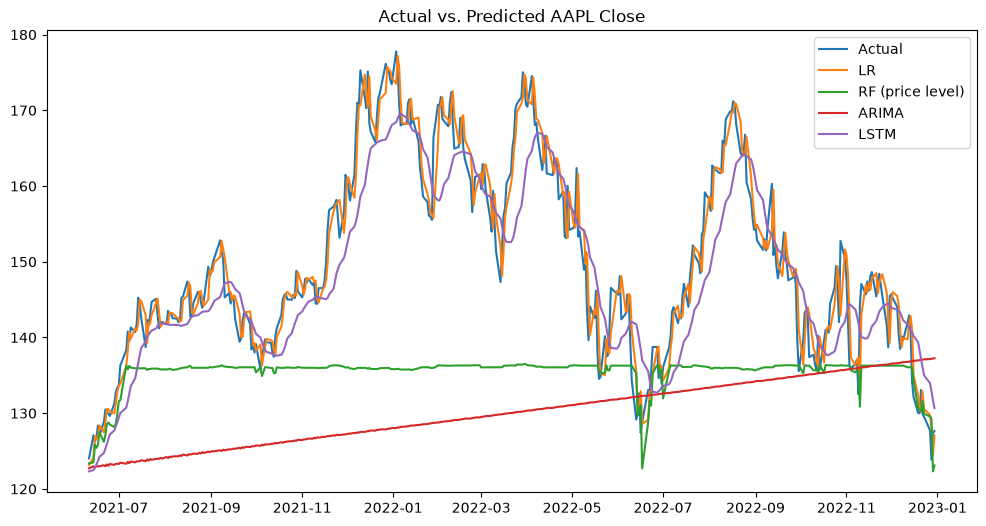

In [24]:
plt.figure(figsize=(12, 6))
plt.plot(y_test.index, y_test, label='Actual')
plt.plot(y_test.index, y_pred_lr, label='LR')
plt.plot(y_test.index, y_pred_rf, label='RF (price level)')
plt.plot(y_test.index, arima_pred, label='ARIMA')
plt.plot(y_test.index[-len(pred_lstm_inv):], pred_lstm_inv, label='LSTM')
plt.legend()
plt.title('Actual vs. Predicted AAPL Close')
plt.show()

In [25]:
comparison = pd.DataFrame([
    {"Model": "Naive (today's price)", **metrics(y_test, naive_pred)},
    {"Model": "Linear Regression", **metrics(y_test, y_pred_lr)},
    {"Model": "Random Forest (price level)", **metrics(y_test, y_pred_rf)},
    {"Model": "Random Forest (returns, reconstructed)", **metrics(y_test_rf_returns, y_pred_rf_returns)},
    {"Model": "ARIMA", **metrics(y_test, arima_pred)},
    {"Model": "LSTM", **metrics(y_test_inv.flatten(), pred_lstm_inv.flatten())},
]).round(4)
comparison

,Model,rmse,mae,mape
0,Naive (today's price),2.9573,2.2387,1.4964
1,Linear Regression,2.9857,2.2707,1.5177
2,Random Forest (price level),18.6093,14.7567,9.3060
3,"Random Forest (returns, reconstructed)",3.6784,2.9413,1.9524
4,ARIMA,23.9167,20.4237,13.0756
5,LSTM,6.0268,4.8836,3.2330


## 11. Model Explainability

C:\Users\azeez\AppData\Local\Temp\ipykernel_42300\816977344.py:5: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test, show=False)


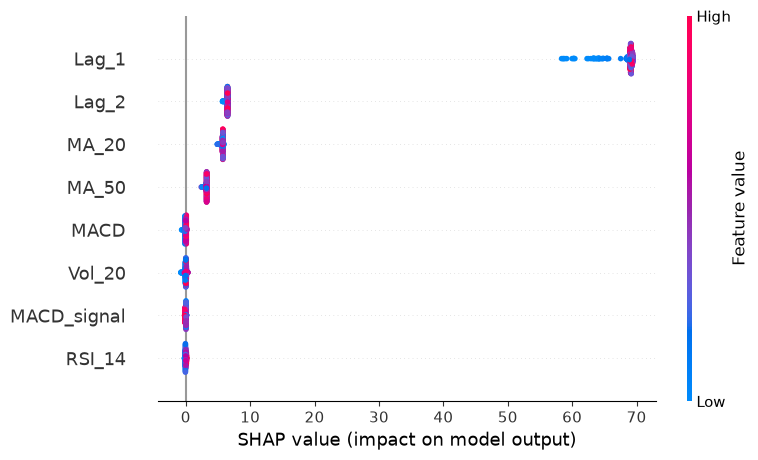

In [26]:
import shap

explainer = shap.TreeExplainer(best_rf)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values, X_test, show=False)
plt.tight_layout()
plt.show()

## 12. Saving Outputs

`models/` and `outputs/` are created in Section 2 — the original notebook only ever created `data/`, so these `joblib.dump()`/`.to_csv()` calls would have raised `FileNotFoundError` on a fresh run.

In [27]:
import joblib

joblib.dump(best_rf, 'models/rf_model.pkl')
joblib.dump(scaler, 'models/scaler.pkl')
model.save('models/lstm_model.keras')
print("Models saved.")

Models saved.


In [28]:
results = pd.DataFrame({
    'y_test': y_test,
    'pred_naive': naive_pred,
    'pred_lr': y_pred_lr,
    'pred_rf_price': y_pred_rf,
    'pred_arima': arima_pred,
    'pred_lstm': pd.Series(
        pred_lstm_inv.flatten(),
        index=y_test.index
    ),
})

results.to_csv('outputs/predictions_comparison.csv', index=True)

# Save the return-based Random Forest results separately
rf_returns_results = pd.DataFrame({
    'actual_next_close': y_test_rf_returns,
    'pred_rf_returns': y_pred_rf_returns,
})

rf_returns_results.to_csv(
    'outputs/rf_returns_predictions.csv',
    index=True
)

print("Predictions saved.")
print("Main predictions:", results.shape)
print("RF-return predictions:", rf_returns_results.shape)

Predictions saved.
Main predictions: (393, 6)
RF-return predictions: (392, 2)


## Limitations

- **No model here beats the naive "tomorrow = today" baseline by a meaningful margin**, once the leakage is fixed. That is the honest finding of this notebook, not a shortcoming of the modeling — it's broadly consistent with daily-frequency stock prices being close to a random walk. Presenting a technical-indicator-based model as having found real predictive edge, without this baseline comparison, is the single easiest way to fool yourself with this kind of dataset.
- **Random Forest on price level is kept in Section 7 deliberately**, alongside the fixed return-based version in 7a, specifically to make the extrapolation failure visible with real numbers — not because it's a recommended way to use tree ensembles on trending series.
- **The LSTM's test-time sequences borrow the last `look_back` days of training data as context** for its first predictions (see Section 9) — a standard, necessary practice for windowed sequence models, but worth knowing it means the very first few test predictions aren't purely "test-period-only" in their inputs.
- **No transaction costs, slippage, or position sizing** are modeled anywhere here — even a genuinely predictive-looking RMSE improvement would need this analysis before it says anything about a viable trading strategy.
- **Single stock, single time period.** Nothing here has been checked against other tickers or market regimes; a technique that looks reasonable on 2015–2022 AAPL data may not generalize even to a different date range for the same stock.